# project: predict whether a customer will buy a smart device 

         we will learn XGBoost classification using a small unique customer dataset
         what is XGBoost means it will work with the week agent only but this will produce one tree first and produce the next tree to overcome the first tree mistake because of that it will work with more accuracy


In [2]:
# install XGBoost
!pip install -q xgboost


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

In [14]:
# create a unique dataset
data = { 
        "age":[21,32,42,52,45,56,76,30,12,45,32,21,24,67,76,90,34,56,45,54],
        "monthly_income":[18000,2000,5000,20000,8000,50000,40000,8000,500000,80000,9000,10000,20000,60000,50000,9000,4000,6000,7000,2000],
        "daily_screen_time":[1,2,5,4,2,3,8,3,9,1,7,1,2,8,3,1,5,1,2,4],
        "tech_interest":[8,4,2,2,5,4,2,3,6,7,5,7,8,9,4,2,1,3,5,6],
        "purchased":[1,1,0,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,0,1]
}
df = pd.DataFrame(data)
df.head()

,age,monthly_income,daily_screen_time,tech_interest,purchased
0,21,18000,1,8,1
1,32,2000,2,4,1
2,42,5000,5,2,0
3,52,20000,4,2,1
4,45,8000,2,5,1


In [15]:
# EDA
df.shape


(20, 5)

In [16]:
df.info

<bound method DataFrame.info of     age  monthly_income  daily_screen_time  tech_interest  purchased
0    21           18000                  1              8          1
1    32            2000                  2              4          1
2    42            5000                  5              2          0
3    52           20000                  4              2          1
4    45            8000                  2              5          1
5    56           50000                  3              4          1
6    76           40000                  8              2          0
7    30            8000                  3              3          0
8    12          500000                  9              6          1
9    45           80000                  1              7          0
10   32            9000                  7              5          1
11   21           10000                  1              7          1
12   24           20000                  2              8          1
13

purchased
1    13
0     7
Name: count, dtype: int64
Axes(0.125,0.11;0.775x0.77)


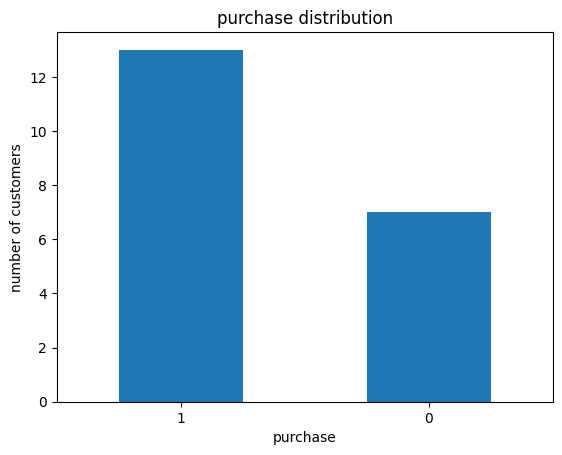

In [18]:
# data visulization


print(df['purchased'].value_counts())
print(df['purchased'].value_counts().plot(kind='bar'))
plt.title("purchase distribution")
plt.xlabel("purchase")
plt.ylabel("number of customers")
plt.xticks(rotation=0)
plt.show()

In [19]:
# separate features and target
X = df.drop('purchased',axis=1)
y = df['purchased']

print('features')
print(X.head())
print('target')
print(y.head())

features
   age  monthly_income  daily_screen_time  tech_interest
0   21           18000                  1              8
1   32            2000                  2              4
2   42            5000                  5              2
3   52           20000                  4              2
4   45            8000                  2              5
target
0    1
1    1
2    0
3    1
4    1
Name: purchased, dtype: int64


In [20]:
# train and test 
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)



# built the model

     n_estimator=100 --> no.of.trees
     max_depth=3 --> max tree depth
     learning_rate=0.1 --> contribution of each new tree
     random_state=42 --> reproducible results


In [21]:
# built the model

model = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
       eval_metric='logloss')
model.fit(X_train,y_train)

print("succesfull")

succesfull


In [23]:
# prediction
y_pred = model.predict(X_test)
print("actual value")
print(y_test.values)
print("predicted value")
print(y_pred)

actual value
[1 0 1 1]
predicted value
[1 1 1 1]


In [24]:
# evaluate the model

accuracy  = accuracy_score(y_test, y_pred)
print("accuracy", accuracy)

print(classification_report(y_test, y_pred, zero_division=0))

accuracy 0.75
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.75      1.00      0.86         3

    accuracy                           0.75         4
   macro avg       0.38      0.50      0.43         4
weighted avg       0.56      0.75      0.64         4



In [27]:
# predict with new dataset

new_customer = pd.DataFrame({
    'age':[29],
    'monthly_income':[50000],
    'daily_screen_time':[9],
    'tech_interest':[9],
    })
prediction = model.predict(new_customer)[0]
probability = model.predict_proba(new_customer)[0][1]

print(round(probability *100, 2))

65.07
